In [1]:
import sys
import os
import numpy as np
import pandas as pd
from IPython.core.pylabtools import figsize
from matplotlib import pyplot as plt


sys.path.append(os.path.join(os.getcwd(), '../../src/'))
from utils_worm import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils

In [2]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)

<module 'utils.train_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/train_utils.py'>

In [3]:
read_ids = list(range(0, 33+1))
# read_ids = [0,   # minrevs
# 				  1,   # minswitch
# 				  7,   # maxswitch
# 				  11,  # median
# 				  12,  # maxrevs
# 				  17,  # mean
# 				  19,  # paper
# 				  21]  # clean
# read_ids = [19]
plot_id = 19

In [4]:
path = os.path.join(read_utils.get_data_path(), 'exported_data_gcamp')

# read
(file_ids, filenames,
 traces,
 continuous_behaviors,
 discrete_states, eigenworms,
 kymographs) = read_utils.get_datas(path, read_ids)

# clear nan values
for i in range(len(file_ids)):
	mask = eigenworms[i].notna().all(axis=1)

	traces[i] = traces[i][mask]
	continuous_behaviors[i] = continuous_behaviors[i][mask]
	eigenworms[i] = eigenworms[i][mask]
	discrete_states[i] = discrete_states[i][mask]
	kymographs[i] = kymographs[i][mask]

# naive ID unknown neurons
for i in range(len(file_ids)):
	traces[i].columns = pd.Index([
		f'{file_ids[i]:02d}_{n_id:03d}' if empty or type(label) is not str else label for n_id, (label, empty) in enumerate(zip(traces[i].columns, traces[i].columns == ''))
	])

# preprocess
pass

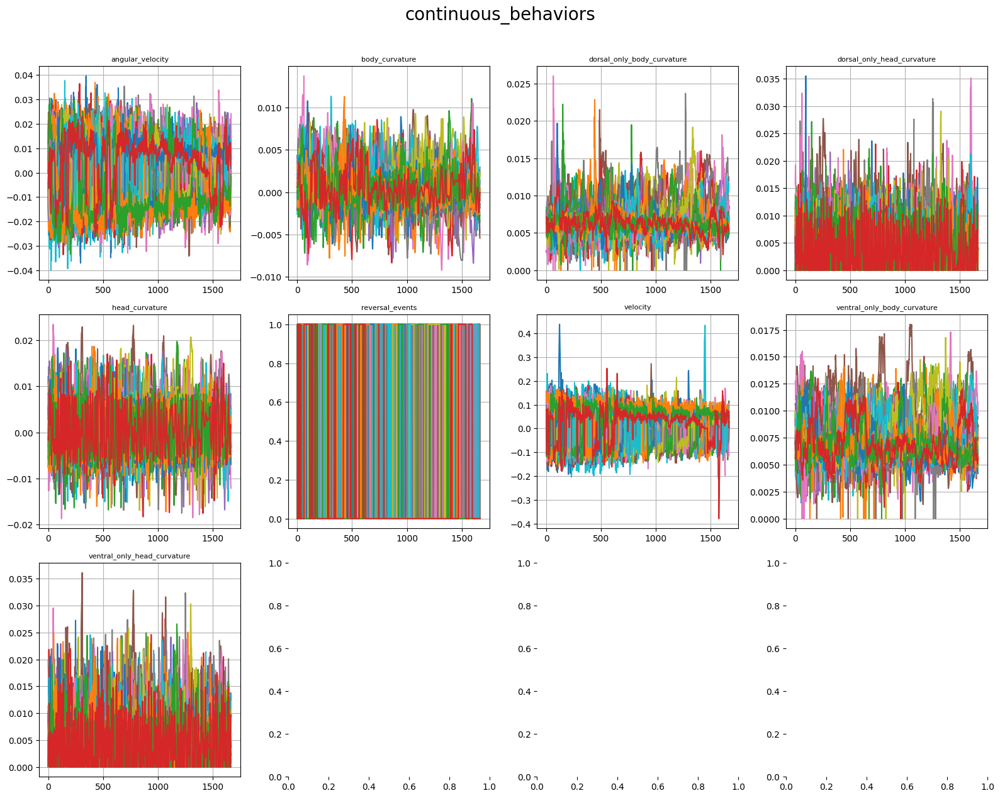

In [5]:
plot_utils.subplot(continuous_behaviors,
				   'continuous_behaviors',
				   n_plots=None)

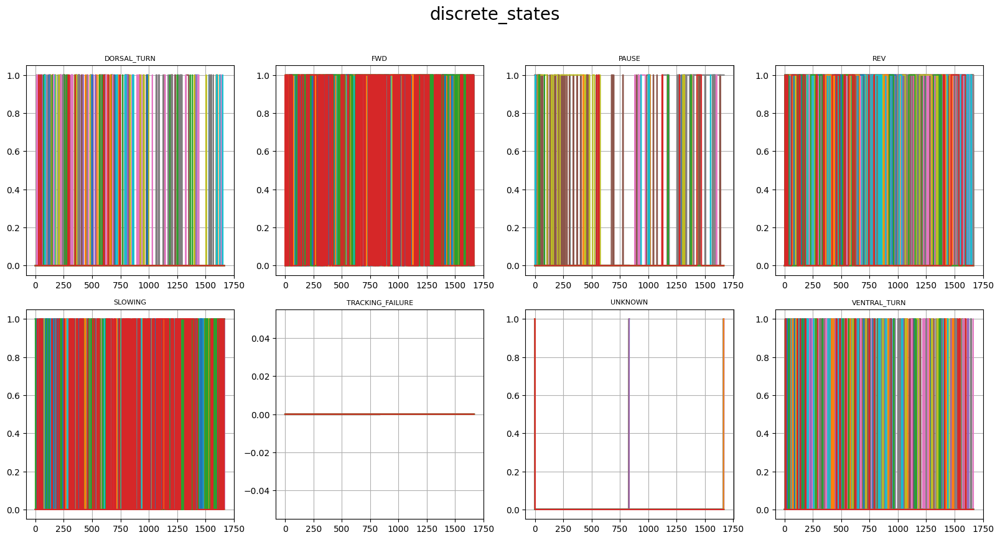

In [6]:
plot_utils.subplot(discrete_states,
				   'discrete_states',
				   n_plots=None)

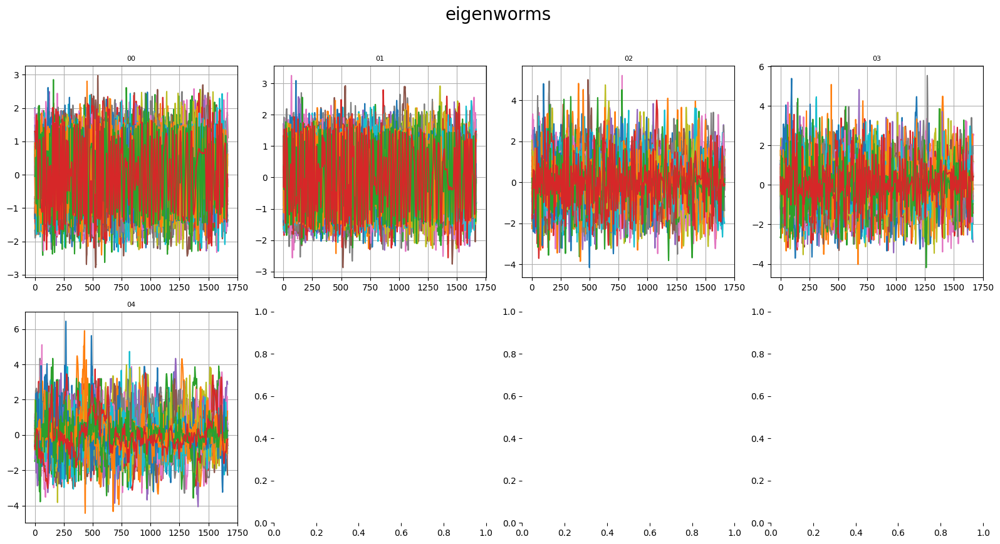

In [7]:
plot_utils.subplot(eigenworms,
				   'eigenworms',
				   n_plots=None)

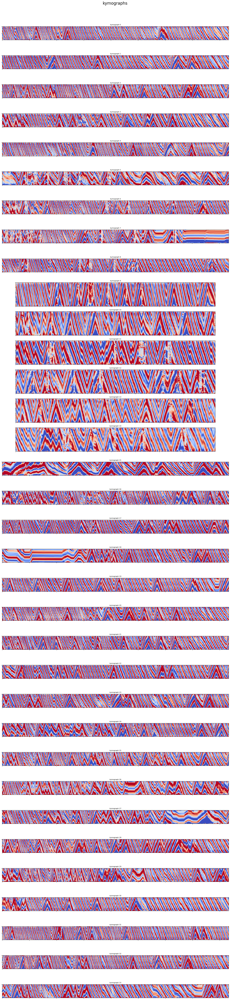

In [8]:
top_space = 2
n_plots = 34

figheight = 2 * n_plots + top_space
fig, axes = plt.subplots(n_plots, 1, figsize=(16, figheight), squeeze=False)
for i in range(n_plots):
	axes[i, 0].set_xticklabels([])
	axes[i, 0].set_yticklabels([])
	axes[i, 0].grid(False)

for i, kymograph in enumerate(kymographs):
	if kymograph is not None:
		axes[i, 0].imshow(np.clip(kymograph, -0.01, 0.01).T, cmap='coolwarm')
	axes[i, 0].set_title(f'kymograph {i}', fontsize=8)

top_space_rel = top_space / figheight
fig.text(0.5, 1. - top_space_rel / 2, 'kymographs', ha='center', fontsize=20)
fig.tight_layout(rect=(0., 0., 1., 1. - top_space_rel))

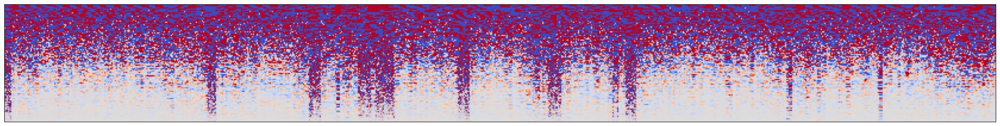

In [28]:
kg = kymographs[9]
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
pca = PCA(n_components=kg.shape[1])
kg_pc = pca.fit_transform(StandardScaler().fit_transform(kg))


plt.figure(figsize=(30, 7.5))
plt.grid(False)
plt.xticks([])
plt.yticks([])
plt.imshow(np.clip(kg_pc.T, -0.01, 0.01), cmap='coolwarm')

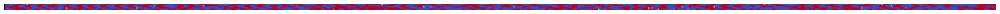

In [21]:
plt.figure(figsize=(30, 7.5))
plt.grid(False)
plt.xticks([])
plt.yticks([])
plt.imshow(np.clip(np.vstack(eigenworms[9].values).T, -0.01, 0.01), cmap='coolwarm')

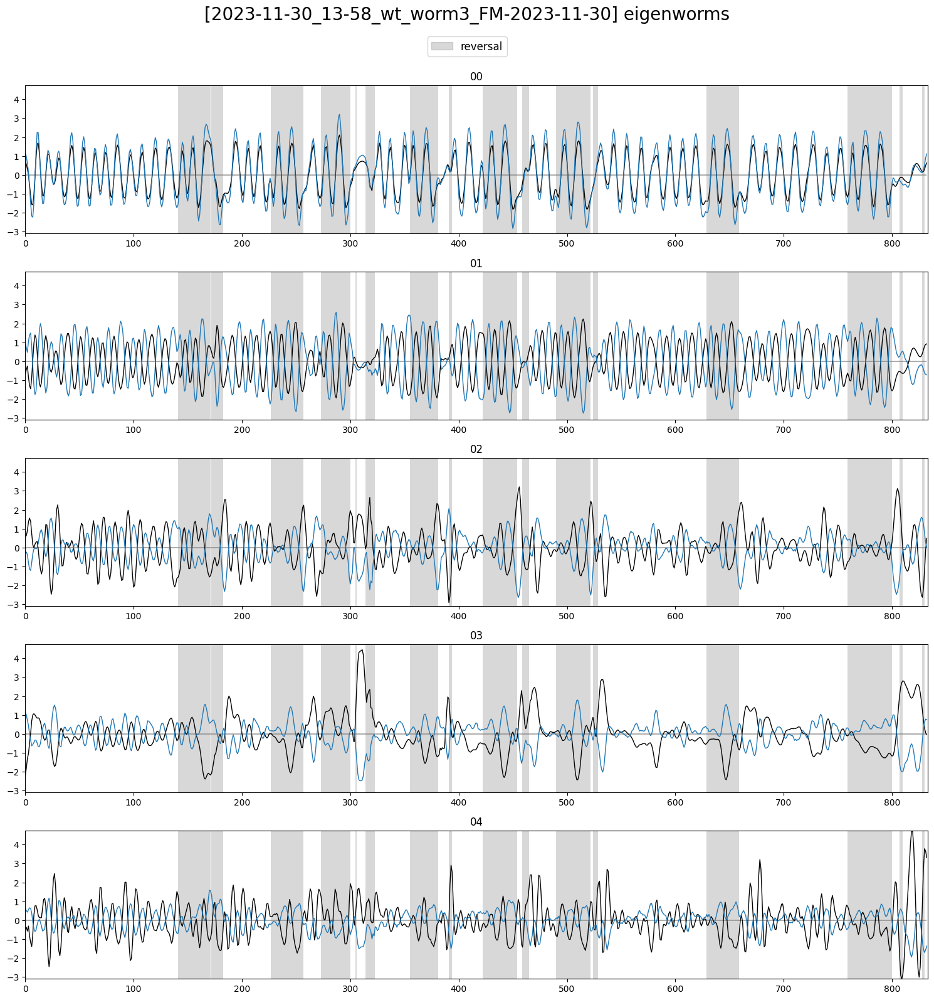

In [32]:
mygenworms = kg_pc[:, :5]
mygenworms /= mygenworms.std()

plot_utils.plot_traces([eigenworms[9],
						pd.DataFrame(mygenworms * -1, columns=eigenworms[9].columns)],
					   discrete_states[9][['REV']],
					   None,
					   label='reversal',
					   title=f'[{filenames[9]}] eigenworms', ylimits=None, plots_per_row=1)